# MLB Hitter Breakout Predictor — Exploratory Data Analysis

## Research Question

Can a hitter's plate discipline and quality of contact help predict future offensive performance and breakout seasons?

This notebook explores historical MLB hitter-season data before any machine-learning models are trained.

### Primary questions

1. Do future breakout hitters show better plate discipline before their breakout?
2. Do future breakout hitters make better contact?
3. Which current-season statistics are most related to next-season wOBA?
4. Does combining plate discipline and contact quality identify breakout candidates better than either category alone?
5. Does the gap between xwOBA and actual wOBA contain useful information about future improvement?

No predictive model is trained in this notebook. The goal is to understand the data, identify potential predictive signal, and develop hypotheses for modeling.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DATA_DIR)
print("Figure output:", FIGURE_DIR)

Project root: /Users/darekstaudt/Desktop/MLB-breakout-predictor
Processed data: /Users/darekstaudt/Desktop/MLB-breakout-predictor/data/processed
Figure output: /Users/darekstaudt/Desktop/MLB-breakout-predictor/outputs/figures


In [3]:
training_file = (
    PROCESSED_DATA_DIR / "training_data.csv"
)

df = pd.read_csv(training_file)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 2422
Columns: 27


,player_id,player_name,season,plate_appearances,bbe,walk_pct,strikeout_pct,whiff_pct,chase_pct,avg_exit_velocity,...,xwoba,xwoba_gap,next_woba,next_xwoba,woba_change,breakout,big_improvement,next_season,current_woba_pct,next_woba_pct
0,605141,"Betts, Mookie",2016,730,599,6.7,11.0,14.2,23.3,89.7,...,0.338,-0.041,0.339,0.340,-0.040,0,0,2017,0.951407,0.683463
1,514888,"Altuve, Jose",2016,717,580,8.4,9.8,15.3,30.7,88.3,...,0.384,-0.007,0.405,0.360,0.014,0,0,2017,0.969309,0.974160
2,456030,"Pedroia, Dustin",2016,698,564,8.7,10.5,12.2,24.7,88.6,...,0.331,-0.027,0.331,0.322,-0.027,0,0,2017,0.855499,0.603359
3,429664,"Canó, Robinson",2016,715,560,6.6,14.0,17.3,34.6,90.1,...,0.348,-0.022,0.334,0.355,-0.036,0,0,2017,0.919437,0.633075
4,444876,"Escobar, Alcides",2016,682,556,4.0,14.1,20.6,38.7,84.0,...,0.262,-0.016,0.269,0.272,-0.009,0,0,2017,0.167519,0.076227


In [4]:
print("Seasons:")
print(sorted(df["season"].unique()))

print()
print("Breakout counts:")
print(df["breakout"].value_counts())

print()
print("Breakout percentage:")
print(
    df["breakout"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Seasons:
[np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Breakout counts:
breakout
0    2229
1     193
Name: count, dtype: int64

Breakout percentage:
breakout
0    92.03
1     7.97
Name: proportion, dtype: float64


In [5]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values(
        "missing_pct",
        ascending=False
    )
)

missing_summary.head(20)

,missing_count,missing_pct
player_id,0,0.0
player_name,0,0.0
season,0,0.0
plate_appearances,0,0.0
bbe,0,0.0
walk_pct,0,0.0
strikeout_pct,0,0.0
whiff_pct,0,0.0
chase_pct,0,0.0
avg_exit_velocity,0,0.0


In [6]:
PLATE_DISCIPLINE_FEATURES = [
    "walk_pct",
    "strikeout_pct",
    "whiff_pct",
    "chase_pct",
]

CONTACT_FEATURES = [
    "avg_exit_velocity",
    "max_exit_velocity",
    "hard_hit_pct",
    "barrel_pct",
    "barrel_per_pa",
    "sweet_spot_pct",
    "avg_launch_angle",
]

PERFORMANCE_FEATURES = [
    "woba",
    "xwoba",
    "xwoba_gap",
]

ALL_FEATURES = (
    PLATE_DISCIPLINE_FEATURES
    + CONTACT_FEATURES
    + PERFORMANCE_FEATURES
)

ALL_FEATURES

['walk_pct',
 'strikeout_pct',
 'whiff_pct',
 'chase_pct',
 'avg_exit_velocity',
 'max_exit_velocity',
 'hard_hit_pct',
 'barrel_pct',
 'barrel_per_pa',
 'sweet_spot_pct',
 'avg_launch_angle',
 'woba',
 'xwoba',
 'xwoba_gap']

In [7]:
df[ALL_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
walk_pct,2422.0,8.494963,3.057694,1.500,6.300,8.300,10.400,23.300
strikeout_pct,2422.0,21.455409,5.857890,3.100,17.300,21.300,25.400,42.800
whiff_pct,2422.0,24.286829,6.041286,5.300,20.200,24.300,28.400,44.300
chase_pct,2422.0,28.368497,6.040716,10.200,24.025,28.100,32.200,51.400
avg_exit_velocity,2422.0,88.824732,2.227655,80.500,87.300,88.900,90.300,97.600
max_exit_velocity,2422.0,110.803427,3.121283,100.200,108.800,110.700,112.900,122.900
hard_hit_pct,2422.0,38.451073,7.918665,8.500,33.300,38.800,43.900,64.200
barrel_pct,2422.0,7.810487,4.179450,0.000,4.700,7.300,10.475,27.500
barrel_per_pa,2422.0,5.207721,2.515029,0.000,3.300,5.000,6.900,15.200
sweet_spot_pct,2422.0,33.812097,3.940558,19.900,31.200,33.800,36.400,49.700


In [8]:
group_means = (
    df
    .groupby("breakout")[ALL_FEATURES]
    .mean()
    .T
)

group_means.columns = [
    "non_breakout_mean",
    "breakout_mean",
]

group_means["difference"] = (
    group_means["breakout_mean"]
    - group_means["non_breakout_mean"]
)

group_means

,non_breakout_mean,breakout_mean,difference
walk_pct,8.525482,8.142487,-0.382995
strikeout_pct,21.363167,22.520725,1.157558
whiff_pct,24.245536,24.763731,0.518194
chase_pct,28.339345,28.705181,0.365836
avg_exit_velocity,88.780754,89.332642,0.551889
max_exit_velocity,110.736698,111.574093,0.837395
hard_hit_pct,38.333423,39.809845,1.476421
barrel_pct,7.782997,8.127979,0.344982
barrel_per_pa,5.192373,5.384974,0.192601
sweet_spot_pct,33.899192,32.806218,-1.092975


In [9]:
def standardized_mean_difference(data, feature):
    breakout = data.loc[
        data["breakout"] == 1,
        feature
    ].dropna()

    non_breakout = data.loc[
        data["breakout"] == 0,
        feature
    ].dropna()

    pooled_sd = np.sqrt(
        (
            breakout.var(ddof=1)
            + non_breakout.var(ddof=1)
        ) / 2
    )

    if pooled_sd == 0:
        return 0

    return (
        breakout.mean()
        - non_breakout.mean()
    ) / pooled_sd

effect_sizes = pd.Series({
    feature: standardized_mean_difference(
        df,
        feature
    )
    for feature in ALL_FEATURES
})

effect_sizes = effect_sizes.sort_values(
    key=np.abs,
    ascending=False
)

effect_sizes

xwoba_gap            0.705081
woba                -0.626590
sweet_spot_pct      -0.274003
max_exit_velocity    0.261017
avg_exit_velocity    0.248357
xwoba               -0.205277
strikeout_pct        0.195624
hard_hit_pct         0.194174
walk_pct            -0.127246
whiff_pct            0.087641
barrel_pct           0.081982
barrel_per_pa        0.076752
chase_pct            0.061317
avg_launch_angle    -0.041520
dtype: float64

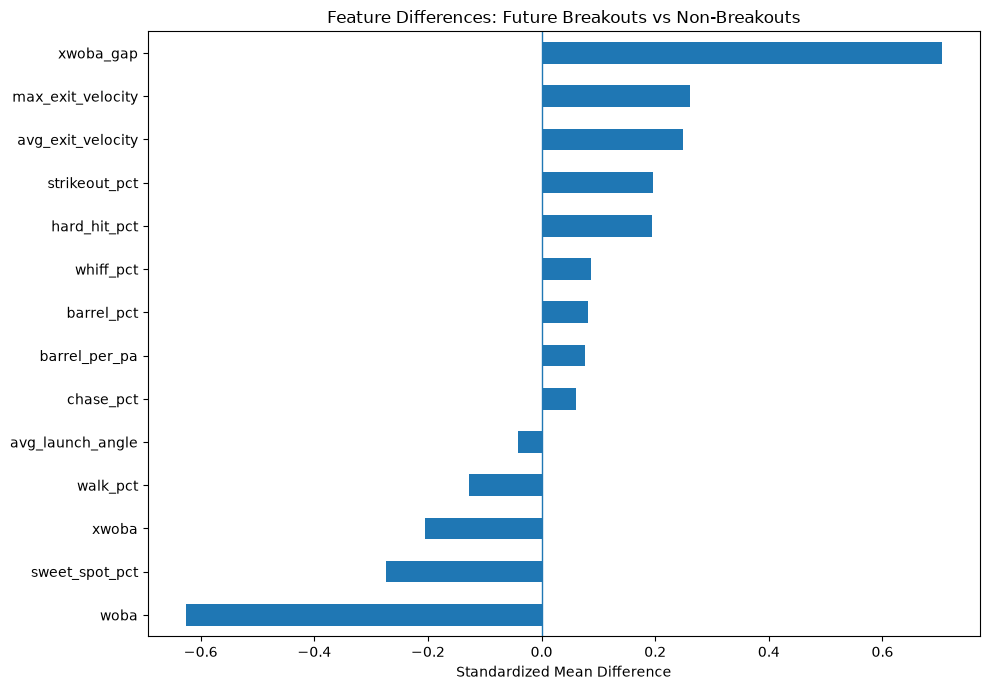

In [10]:
plt.figure(figsize=(10, 7))

effect_sizes.sort_values().plot(
    kind="barh"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Feature Differences: Future Breakouts vs Non-Breakouts"
)

plt.xlabel(
    "Standardized Mean Difference"
)

plt.ylabel("")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "breakout_feature_effect_sizes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [11]:
feature_summary = group_means.copy()

feature_summary[
    "standardized_difference"
] = effect_sizes

feature_summary = (
    feature_summary
    .sort_values(
        "standardized_difference",
        key=np.abs,
        ascending=False
    )
)

feature_summary.to_csv(
    PROCESSED_DATA_DIR
    / "eda_breakout_feature_summary.csv"
)

feature_summary

,non_breakout_mean,breakout_mean,difference,standardized_difference
xwoba_gap,-0.001288,0.013057,0.014345,0.705081
woba,0.323791,0.302337,-0.021454,-0.626590
sweet_spot_pct,33.899192,32.806218,-1.092975,-0.274003
max_exit_velocity,110.736698,111.574093,0.837395,0.261017
avg_exit_velocity,88.780754,89.332642,0.551889,0.248357
xwoba,0.322503,0.315394,-0.007110,-0.205277
strikeout_pct,21.363167,22.520725,1.157558,0.195624
hard_hit_pct,38.333423,39.809845,1.476421,0.194174
walk_pct,8.525482,8.142487,-0.382995,-0.127246
whiff_pct,24.245536,24.763731,0.518194,0.087641


## Engineered Plate Discipline and Contact Quality Scores

To test whether overall plate discipline and contact quality interact, two composite features are created.

### Plate Discipline Score

Higher values represent better plate discipline and combine:

- higher BB%
- lower K%
- lower Whiff%
- lower Chase%

### Contact Quality Score

Higher values represent stronger contact and combine:

- Average Exit Velocity
- Hard-Hit%
- Barrel%
- Sweet-Spot%

Each component is standardized relative to hitters from the same MLB season before being combined. This prevents changes in league-wide offensive environments from unfairly affecting comparisons across seasons.

These scores are custom features created for this project and are not official MLB statistics.

In [12]:
def season_zscore(series):
    std = series.std(ddof=0)

    if std == 0:
        return pd.Series(
            0,
            index=series.index
        )

    return (
        series - series.mean()
    ) / std

In [13]:
df["z_walk_pct"] = (
    df.groupby("season")["walk_pct"]
    .transform(season_zscore)
)

df["z_strikeout_pct"] = (
    df.groupby("season")["strikeout_pct"]
    .transform(season_zscore)
)

df["z_whiff_pct"] = (
    df.groupby("season")["whiff_pct"]
    .transform(season_zscore)
)

df["z_chase_pct"] = (
    df.groupby("season")["chase_pct"]
    .transform(season_zscore)
)

In [14]:
df["plate_discipline_score"] = (
    df["z_walk_pct"]
    - df["z_strikeout_pct"]
    - df["z_whiff_pct"]
    - df["z_chase_pct"]
) / 4

df[
    [
        "player_name",
        "season",
        "walk_pct",
        "strikeout_pct",
        "whiff_pct",
        "chase_pct",
        "plate_discipline_score",
    ]
].sort_values(
    "plate_discipline_score",
    ascending=False
).head(20)

,player_name,season,walk_pct,strikeout_pct,whiff_pct,chase_pct,plate_discipline_score
954,"Soto, Juan",2021,22.2,14.2,20.0,12.2,2.250451
1258,"Soto, Juan",2022,20.3,14.5,19.4,17.3,2.098981
324,"Votto, Joey",2017,19.0,11.7,15.4,13.1,2.095703
1277,"Díaz, Yandy",2022,14.0,10.8,14.3,19.7,1.820883
1226,"Bregman, Alex",2022,13.3,11.7,14.9,18.0,1.763658
1876,"Kwan, Steven",2024,9.8,9.4,8.2,19.1,1.758622
63,"Zobrist, Ben",2016,15.2,13.0,12.8,19.0,1.755459
2128,"Perdomo, Geraldo",2025,13.1,11.5,12.0,19.1,1.742235
680,"Votto, Joey",2018,17.3,16.2,17.9,13.1,1.737649
2046,"Tucker, Kyle",2024,16.5,15.9,19.0,17.5,1.717413


In [15]:
CONTACT_SCORE_FEATURES = [
    "avg_exit_velocity",
    "hard_hit_pct",
    "barrel_pct",
    "sweet_spot_pct",
]

for feature in CONTACT_SCORE_FEATURES:
    df[
        f"z_{feature}"
    ] = (
        df
        .groupby("season")[feature]
        .transform(season_zscore)
    )

In [16]:
df["contact_quality_score"] = (
    df[
        [
            "z_avg_exit_velocity",
            "z_hard_hit_pct",
            "z_barrel_pct",
            "z_sweet_spot_pct",
        ]
    ]
    .mean(axis=1)
)

df[
    [
        "player_name",
        "season",
        "avg_exit_velocity",
        "hard_hit_pct",
        "barrel_pct",
        "sweet_spot_pct",
        "contact_quality_score",
    ]
].sort_values(
    "contact_quality_score",
    ascending=False
).head(20)

,player_name,season,avg_exit_velocity,hard_hit_pct,barrel_pct,sweet_spot_pct,contact_quality_score
1726,"Judge, Aaron",2023,97.6,64.2,27.5,37.1,3.108633
1288,"Judge, Aaron",2022,95.9,61.9,26.5,39.0,3.089012
1912,"Judge, Aaron",2024,96.2,61.0,26.9,40.8,3.084725
435,"Judge, Aaron",2017,95.0,54.7,25.7,38.2,2.994706
1316,"Alvarez, Yordan",2022,95.2,59.8,21.0,40.7,2.700060
896,"Voit, Luke",2018,93.0,54.0,20.0,46.0,2.616136
1840,"Ohtani, Shohei",2024,95.8,60.1,21.5,37.8,2.484480
2224,"Judge, Aaron",2025,95.4,58.2,24.7,39.4,2.457604
549,"Avila, Alex",2017,91.0,50.8,15.0,49.7,2.453424
511,"Gallo, Joey",2017,93.3,52.2,22.1,36.0,2.352055


In [17]:
df.groupby(
    "breakout"
)[
    [
        "plate_discipline_score",
        "contact_quality_score"
    ]
].mean()

,plate_discipline_score,contact_quality_score
breakout,,
0,0.009722,-0.005577
1,-0.112284,0.064413


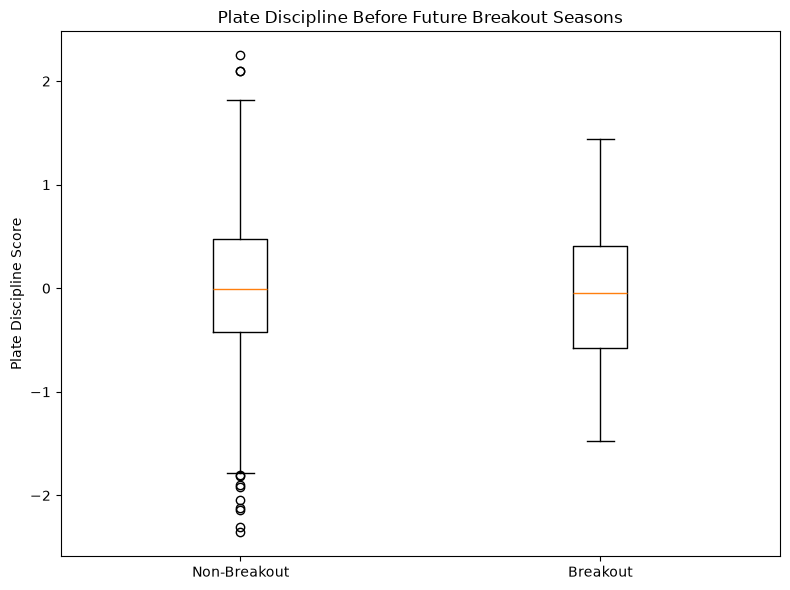

In [18]:
non_breakout_plate = df.loc[
    df["breakout"] == 0,
    "plate_discipline_score"
].dropna()

breakout_plate = df.loc[
    df["breakout"] == 1,
    "plate_discipline_score"
].dropna()

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        non_breakout_plate,
        breakout_plate,
    ],
    tick_labels=[
        "Non-Breakout",
        "Breakout",
    ]
)

plt.title(
    "Plate Discipline Before Future Breakout Seasons"
)

plt.ylabel(
    "Plate Discipline Score"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "plate_discipline_breakout_boxplot.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

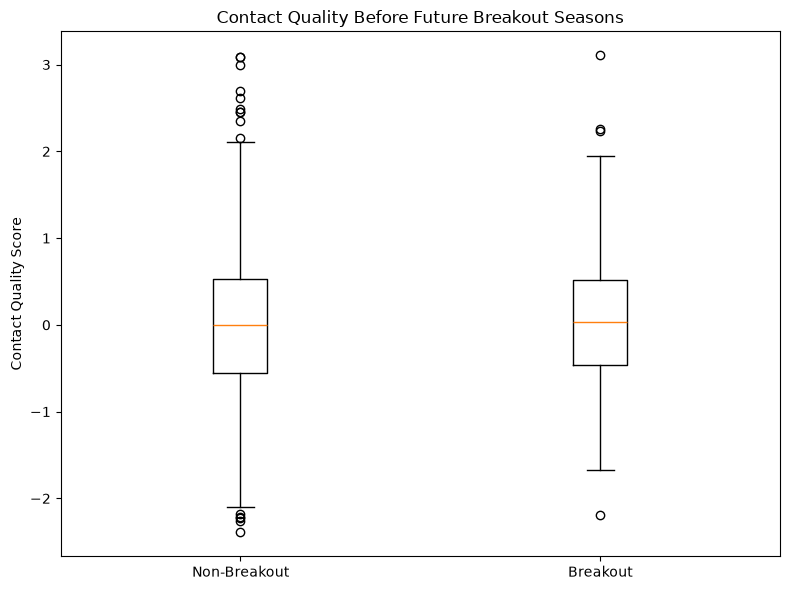

In [19]:
non_breakout_contact = df.loc[
    df["breakout"] == 0,
    "contact_quality_score"
].dropna()

breakout_contact = df.loc[
    df["breakout"] == 1,
    "contact_quality_score"
].dropna()

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        non_breakout_contact,
        breakout_contact,
    ],
    tick_labels=[
        "Non-Breakout",
        "Breakout",
    ]
)

plt.title(
    "Contact Quality Before Future Breakout Seasons"
)

plt.ylabel(
    "Contact Quality Score"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "contact_quality_breakout_boxplot.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [20]:
df["plate_score_percentile"] = (
    df
    .groupby("season")[
        "plate_discipline_score"
    ]
    .rank(pct=True)
)

df["contact_score_percentile"] = (
    df
    .groupby("season")[
        "contact_quality_score"
    ]
    .rank(pct=True)
)

In [21]:
high_plate = (
    df["plate_score_percentile"] >= 0.75
)

high_contact = (
    df["contact_score_percentile"] >= 0.75
)

df["profile_group"] = np.select(
    [
        high_plate & high_contact,
        high_plate & ~high_contact,
        ~high_plate & high_contact,
    ],
    [
        "Top 25% Both",
        "Top 25% Discipline Only",
        "Top 25% Contact Only",
    ],
    default="Neither Top 25%",
)

In [22]:
profile_results = (
    df
    .groupby("profile_group")
    .agg(
        hitters=(
            "breakout",
            "size"
        ),
        breakouts=(
            "breakout",
            "sum"
        ),
        breakout_rate=(
            "breakout",
            "mean"
        ),
        avg_woba_change=(
            "woba_change",
            "mean"
        ),
        avg_next_woba=(
            "next_woba",
            "mean"
        ),
    )
)

profile_results[
    "breakout_rate_pct"
] = (
    profile_results["breakout_rate"]
    * 100
)

profile_results.sort_values(
    "breakout_rate_pct",
    ascending=False
)

,hitters,breakouts,breakout_rate,avg_woba_change,avg_next_woba,breakout_rate_pct
profile_group,,,,,,
Neither Top 25%,1313,117,0.089109,-0.000166,0.307513,8.910891
Top 25% Contact Only,498,39,0.078313,-0.013811,0.331594,7.831325
Top 25% Discipline Only,498,32,0.064257,-0.006018,0.318265,6.425703
Top 25% Both,113,5,0.044248,-0.023513,0.353416,4.424779


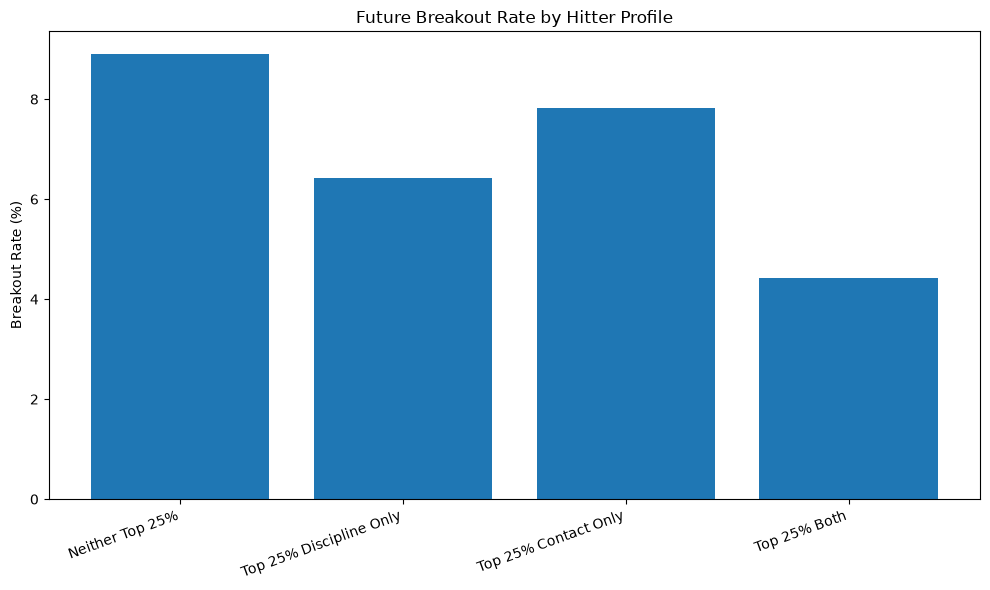

In [23]:
profile_order = [
    "Neither Top 25%",
    "Top 25% Discipline Only",
    "Top 25% Contact Only",
    "Top 25% Both",
]

profile_chart = (
    profile_results
    .reindex(profile_order)
)

plt.figure(figsize=(10, 6))

plt.bar(
    profile_chart.index,
    profile_chart[
        "breakout_rate_pct"
    ]
)

plt.title(
    "Future Breakout Rate by Hitter Profile"
)

plt.ylabel(
    "Breakout Rate (%)"
)

plt.xlabel("")

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "breakout_rate_by_profile.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [24]:
correlations_next_woba = (
    df[
        ALL_FEATURES
        + ["next_woba"]
    ]
    .corr(numeric_only=True)[
        "next_woba"
    ]
    .drop("next_woba")
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

correlations_next_woba

xwoba                0.497282
woba                 0.447170
avg_exit_velocity    0.376730
barrel_per_pa        0.363080
hard_hit_pct         0.345874
barrel_pct           0.340359
max_exit_velocity    0.338838
walk_pct             0.277285
chase_pct           -0.141195
sweet_spot_pct       0.122718
avg_launch_angle     0.061826
xwoba_gap            0.048406
strikeout_pct       -0.048202
whiff_pct            0.000094
Name: next_woba, dtype: float64

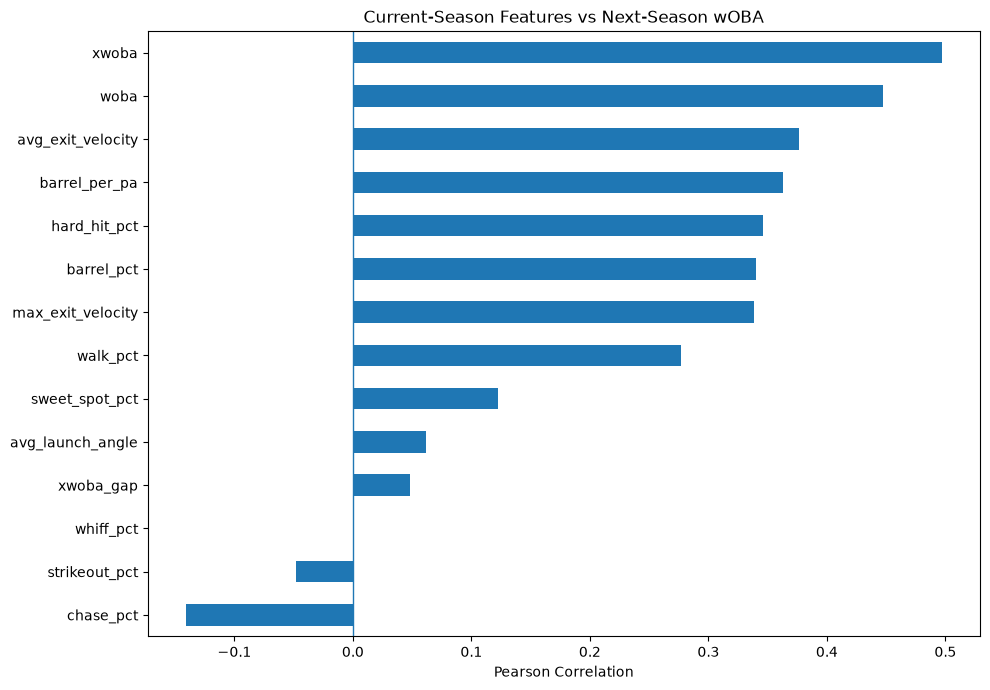

In [25]:
plt.figure(figsize=(10, 7))

correlations_next_woba.sort_values().plot(
    kind="barh"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Current-Season Features vs Next-Season wOBA"
)

plt.xlabel(
    "Pearson Correlation"
)

plt.ylabel("")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "feature_correlations_next_woba.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [26]:
correlations_change = (
    df[
        ALL_FEATURES
        + ["woba_change"]
    ]
    .corr(numeric_only=True)[
        "woba_change"
    ]
    .drop("woba_change")
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

correlations_change

woba                -0.501649
xwoba_gap            0.383618
xwoba               -0.301075
sweet_spot_pct      -0.193203
barrel_per_pa       -0.161090
barrel_pct          -0.154851
walk_pct            -0.151654
hard_hit_pct        -0.100545
avg_exit_velocity   -0.093064
chase_pct            0.081576
avg_launch_angle    -0.053870
strikeout_pct        0.049167
max_exit_velocity   -0.043872
whiff_pct           -0.008985
Name: woba_change, dtype: float64

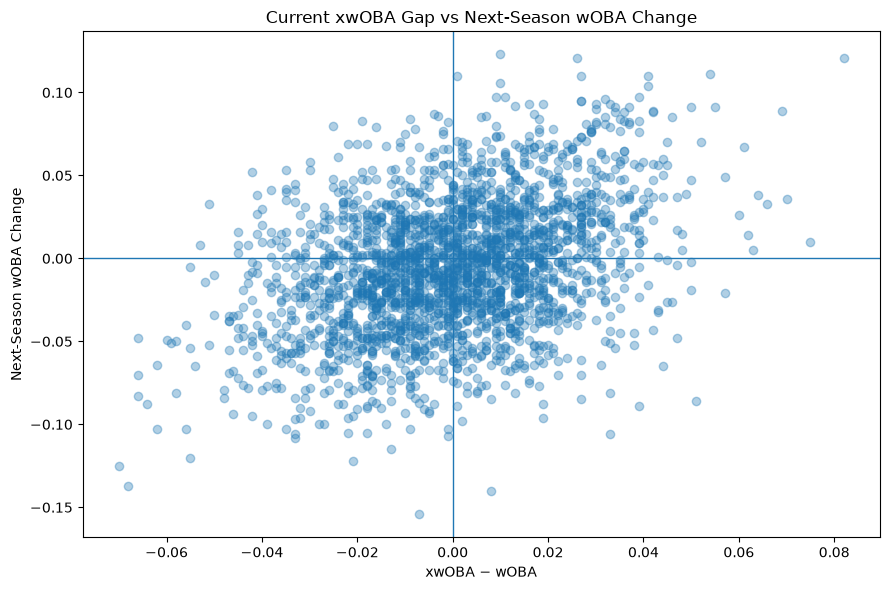

Correlation between xwOBA gap and future wOBA change: 0.384


In [27]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["xwoba_gap"],
    df["woba_change"],
    alpha=0.35
)

plt.axhline(
    0,
    linewidth=1
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Current xwOBA Gap vs Next-Season wOBA Change"
)

plt.xlabel(
    "xwOBA − wOBA"
)

plt.ylabel(
    "Next-Season wOBA Change"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "xwoba_gap_vs_future_change.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

xwoba_gap_corr = (
    df[
        [
            "xwoba_gap",
            "woba_change"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlation between xwOBA gap "
    "and future wOBA change:",
    round(xwoba_gap_corr, 3)
)

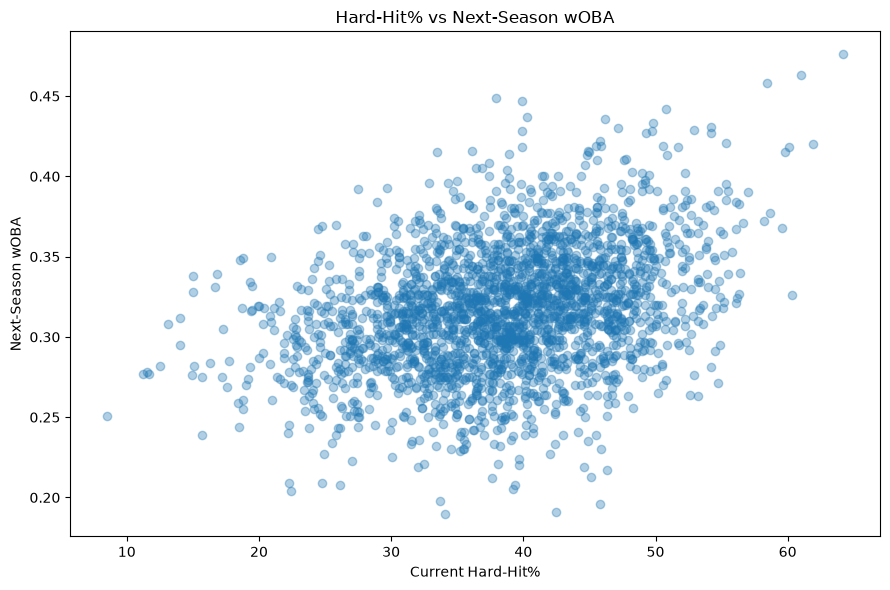

In [28]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["hard_hit_pct"],
    df["next_woba"],
    alpha=0.35
)

plt.title(
    "Hard-Hit% vs Next-Season wOBA"
)

plt.xlabel(
    "Current Hard-Hit%"
)

plt.ylabel(
    "Next-Season wOBA"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "hard_hit_vs_next_woba.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

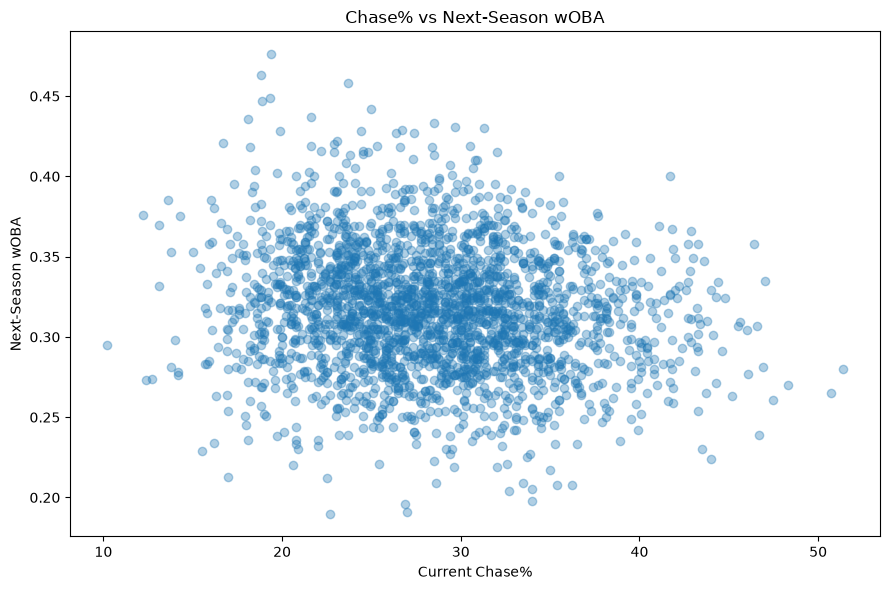

In [29]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["chase_pct"],
    df["next_woba"],
    alpha=0.35
)

plt.title(
    "Chase% vs Next-Season wOBA"
)

plt.xlabel(
    "Current Chase%"
)

plt.ylabel(
    "Next-Season wOBA"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "chase_vs_next_woba.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

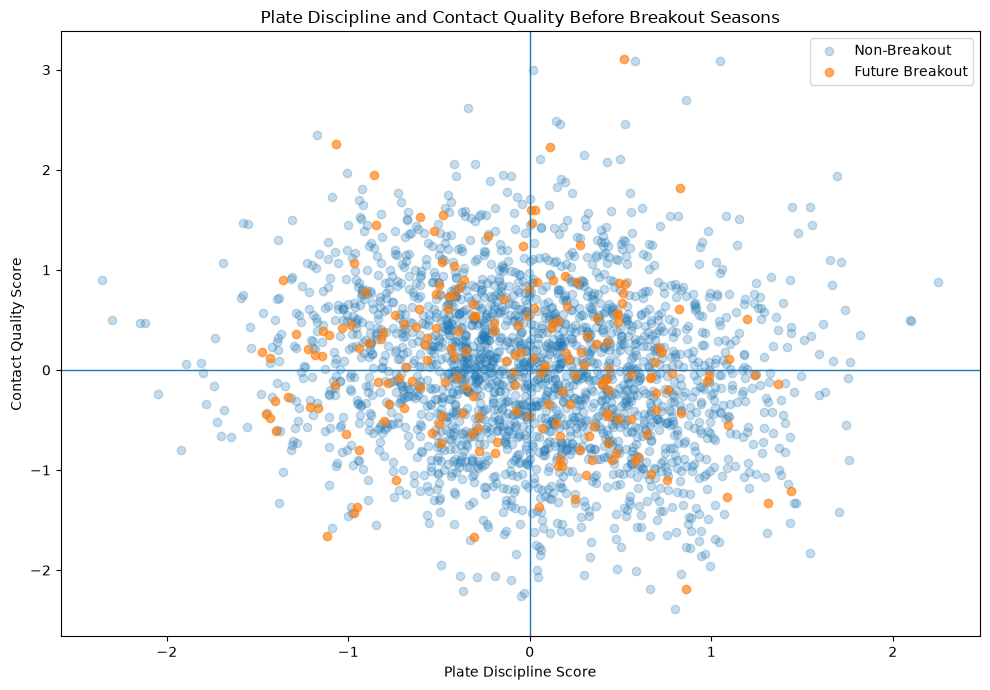

In [30]:
non_breakouts = df[
    df["breakout"] == 0
]

breakouts = df[
    df["breakout"] == 1
]

plt.figure(figsize=(10, 7))

plt.scatter(
    non_breakouts[
        "plate_discipline_score"
    ],
    non_breakouts[
        "contact_quality_score"
    ],
    alpha=0.25,
    label="Non-Breakout"
)

plt.scatter(
    breakouts[
        "plate_discipline_score"
    ],
    breakouts[
        "contact_quality_score"
    ],
    alpha=0.65,
    label="Future Breakout"
)

plt.axvline(
    0,
    linewidth=1
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Plate Discipline and Contact Quality Before Breakout Seasons"
)

plt.xlabel(
    "Plate Discipline Score"
)

plt.ylabel(
    "Contact Quality Score"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "discipline_contact_breakout_scatter.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [31]:
eda_file = (
    PROCESSED_DATA_DIR
    / "training_data_enriched.csv"
)

df.to_csv(
    eda_file,
    index=False
)

print(
    "Saved enriched training data to:",
    eda_file
)

Saved enriched training data to: /Users/darekstaudt/Desktop/MLB-breakout-predictor/data/processed/training_data_enriched.csv


In [32]:
eda_summary = pd.DataFrame({
    "correlation_next_woba":
        correlations_next_woba,
    "correlation_woba_change":
        correlations_change,
    "standardized_breakout_difference":
        effect_sizes,
})

eda_summary = (
    eda_summary
    .sort_values(
        "correlation_next_woba",
        key=np.abs,
        ascending=False
    )
)

eda_summary

eda_summary.to_csv(
    PROCESSED_DATA_DIR
    / "eda_feature_relationships.csv"
)

## Baseline-Adjusted Improvement

In [33]:
from sklearn.linear_model import LinearRegression

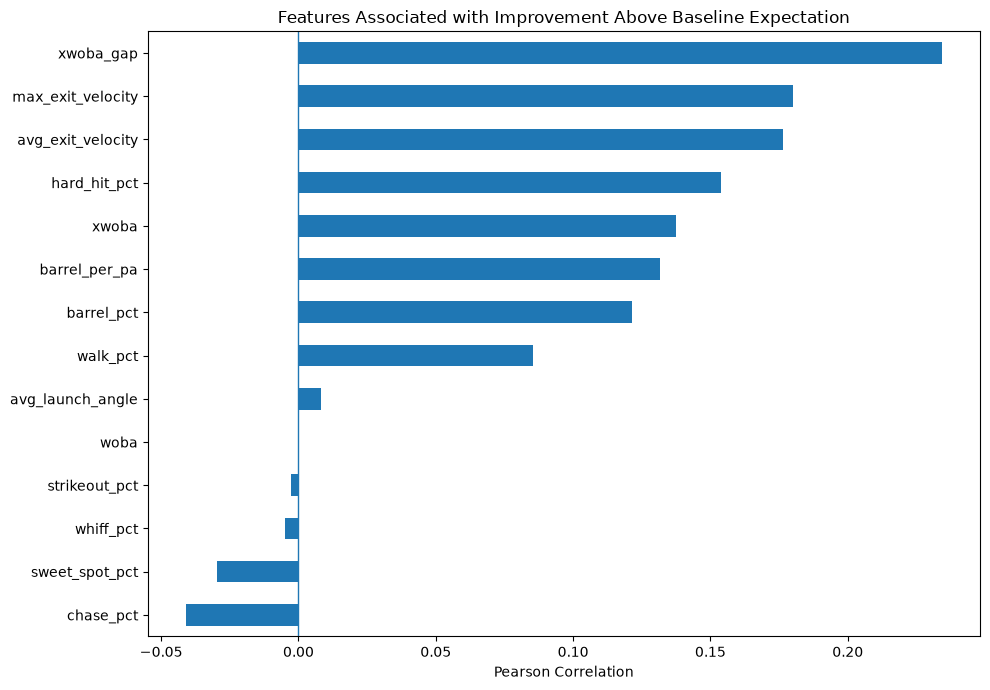

In [34]:
baseline_improvement_model = LinearRegression()

X_baseline = df[["woba"]]
y_change = df["woba_change"]

baseline_improvement_model.fit(
    X_baseline,
    y_change
)

df["expected_woba_change"] = (
    baseline_improvement_model.predict(
        X_baseline
    )
)

df["improvement_above_expectation"] = (
    df["woba_change"]
    - df["expected_woba_change"]
)

adjusted_correlations = (
    df[
        ALL_FEATURES
        + ["improvement_above_expectation"]
    ]
    .corr(numeric_only=True)[
        "improvement_above_expectation"
    ]
    .drop("improvement_above_expectation")
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

adjusted_correlations

plt.figure(figsize=(10, 7))

adjusted_correlations.sort_values().plot(
    kind="barh"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Features Associated with Improvement Above Baseline Expectation"
)

plt.xlabel(
    "Pearson Correlation"
)

plt.ylabel("")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "features_vs_adjusted_improvement.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Exploratory Analysis Conclusions

### Plate Discipline

In my analysis, plate-discipline metrics showed mixed relationships with future offensive performance. A higher walk rate was associated with stronger next-season performance and with improvement above baseline expectation. A lower Chase% was also associated with better future performance, although the relationship was not especially strong.

Strikeout% and Whiff% showed relatively weak relationships with next-season wOBA and adjusted improvement. Based on these results, I do not think plate discipline alone is enough to identify future breakout hitters. However, I do think it provides useful information when it is combined with other hitting metrics.

### Contact Quality

Contact-quality metrics showed stronger and more consistent relationships with future performance.

I found that Average Exit Velocity, Maximum Exit Velocity, Hard-Hit%, Barrel%, and Barrels per Plate Appearance were all positively related to next-season wOBA. These relationships also remained meaningful after I adjusted year-over-year improvement based on how well the hitter was already performing.

Maximum Exit Velocity, Average Exit Velocity, and Hard-Hit% were some of the strongest contact-quality variables associated with improvement above baseline expectation. This suggests that hitters who are already showing the ability to produce high-quality contact may have underlying offensive ability that is not fully reflected in their current results.

### Combined Hitter Profile

I created a Plate Discipline Score and Contact Quality Score to test whether hitters who were strong in both areas were especially likely to break out.

Hitters who ranked in the top 25% in both scores had the highest average next-season wOBA, at approximately .353. However, this same group had the lowest breakout rate based on my breakout definition.

I do not think this means that strong discipline and strong contact are negative indicators. Instead, I think it shows a ceiling effect. Hitters who are already strong in both categories are usually already productive, so they have less room to make the approximately 45-point increase in wOBA required to qualify as a breakout.

Because of this, I think the combined scores may be more useful for identifying hitters who are likely to remain strong offensive players than for identifying the largest year-over-year improvements.

### xwOBA Gap

The difference between xwOBA and actual wOBA was the strongest individual feature separating future breakout hitters from non-breakout hitters.

At first, I was cautious about this result because both xwOBA gap and year-over-year wOBA change use current-season wOBA in their calculations. This creates the possibility that part of the relationship is caused by regression toward the mean rather than true predictive information.

To account for this, I created a baseline model that estimated the amount of improvement normally expected based only on current-season wOBA. I then calculated how much each hitter improved above or below that expectation.

Even after making this adjustment, xwOBA gap remained the feature most strongly associated with improvement above expectation.

This gives me more confidence that hitters whose expected performance is better than their actual results may be legitimate candidates for future improvement. However, I still interpret this as an association rather than evidence that xwOBA gap directly causes a breakout.

### Baseline-Adjusted Improvement

After adjusting improvement based on current-season wOBA, several important relationships remained.

xwOBA gap had the strongest positive relationship with improvement above expectation. Maximum Exit Velocity, Average Exit Velocity, Hard-Hit%, xwOBA, Barrel%, and Barrels per Plate Appearance also showed positive relationships.

Current-season wOBA itself had almost no remaining relationship with adjusted improvement, which makes sense because my baseline model already accounted for current performance.

This result suggests to me that quality-of-contact information provides additional information about future improvement beyond simply knowing how well the player performed during the current season.

### Most Promising Predictive Features

Based on my exploratory analysis, I identified two slightly different groups of useful predictors.

For predicting **overall next-season offensive performance**, the strongest features appear to include:

- xwOBA
- Current wOBA
- Average Exit Velocity
- Barrels per Plate Appearance
- Hard-Hit%
- Barrel%
- Maximum Exit Velocity
- Walk%
- Chase%

For identifying hitters who may **improve more than expected**, the most promising features appear to include xwOBA gap and several contact-quality measures, especially Maximum Exit Velocity, Average Exit Velocity, and Hard-Hit%.

### Overall Finding

My original hypothesis was that hitters with both elite plate discipline and elite contact quality would be the most likely to have breakout seasons.

The data did not fully support that idea in the simple way I originally expected.

Instead, I found a more interesting pattern. Strong plate discipline and strong contact quality were associated with better future offensive performance, but the largest year-over-year improvements tended to come from hitters whose current results did not fully match their underlying expected statistics and contact quality.

Based on these results, I think the most interesting breakout candidate is not necessarily a hitter who is already excellent in every category. It may instead be a hitter whose current performance looks average or disappointing, but whose Statcast metrics suggest that he is making better contact and producing better underlying results than his traditional statistics show.

### Modeling Implications

Based on this exploratory analysis, I will use next-season wOBA as the main prediction target rather than trying to predict only a binary breakout label.

In the modeling stage, I plan to compare several different feature sets:

1. A simple baseline based on current performance.
2. Plate-discipline features only.
3. Contact-quality features only.
4. Combined plate-discipline and contact-quality features.
5. A full model that includes current wOBA, xwOBA, and Statcast metrics.

I will evaluate the models chronologically so that future-season information is never used to predict earlier seasons. I will also compare every model against a simple baseline to determine whether the additional Statcast and plate-discipline information actually improves prediction accuracy.

After selecting the strongest model, I will apply it to 2026 hitters to estimate their 2027 wOBA and identify players whose predicted performance represents a meaningful improvement over their 2026 results.

## Summary

This notebook explored how plate-discipline, contact-quality, and offensive-performance metrics relate to future MLB hitter performance.

The analysis showed that contact-quality metrics generally had stronger relationships with next-season wOBA than plate-discipline metrics alone. xwOBA and current wOBA were also among the strongest predictors of future performance.

The original hypothesis that hitters with both elite plate discipline and elite contact quality would experience the largest breakouts was not fully supported. Those hitters tended to remain strong overall performers, but they often had less room for large year-over-year improvement.

After accounting for expected improvement based on current wOBA, xwOBA gap and several contact-quality metrics still showed useful relationships with improvement above expectation.

These findings were used to choose the feature sets evaluated in the modeling notebook.